# Detección generativa de degradación de suelo en monocultivos de pino (VAE) — v2

| Sección | Qué hace |
|---|---|
| 0 | Configuración (todo lo que se ajusta está aquí) |
| 1 | Extracción GEE: 3 compuestos (verano pre, otoño pre 2022, otoño post 2023), pendiente, pino, quemado dNBR y quemado de referencia (MODIS o perímetros) |
| 2 | Control de calidad del raster |
| 3 | Parches 64×64 (solapados en train), split espacial por bloques |
| 4 | Exploración del dataset |
| 5 | Dataset, DataLoader, VAE y función de entrenamiento |
| 6 | **E1 – Baseline** con evaluación completa |
| 7 | **Experimentos E2–E7** (colapso posterior, VAE vs AE, sobreajuste, estacionalidad, circularidad, semillas) |
| 8 | Mapa de puntaje de anomalía (objetivo 3) |
| 9 | Resumen final |

Todas las figuras se guardan en `runs/figs/` (PNG listos para las diapositivas) y todos los resultados en `runs/experimentos.csv`.

**Uso:** con `USE_SYNTHETIC = True` genera datos falsos para probar que todo corre (los números no significan nada). Con datos reales: `USE_SYNTHETIC = False` y los `.tif` exportados desde GEE en `RAW_DIR`.

## 0. Configuración

In [7]:
# Si falta algo, ejecuta una vez y reinicia el kernel:
# %pip install torch scikit-learn rasterio numpy pandas matplotlib scipy earthengine-api

import copy, glob, json, os, time, zlib
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score, roc_curve

# ---------- Rutas ----------
RAW_DIR = "./data/raw"          # GeoTIFF exportados desde GEE
OUT_DIR = "./data/processed"    # parches.npz
RUN_DIR = "./runs"              # modelos (.pt), resultados (.json/.csv)
FIG_DIR = "./runs/figs"         # figuras PNG para la presentacion

# ---------- Modo ----------
USE_SYNTHETIC = False         # True = datos falsos solo para probar el pipeline
REHACER_PARCHES = True          # False = reutiliza parches.npz si existe
REPETIR_EXPERIMENTOS = False    # False = no re-entrena experimentos ya hechos con este mismo dataset

# ---------- Google Earth Engine ----------
RUN_GEE = False                 # True solo para volver a exportar desde GEE (los .tif ya van en data/raw)
GEE_PROJECT = "proyecto-erosion-pino"
PINE_ASSET = None               # ej. "projects/TU_PROYECTO/assets/catastro_conaf_biobio"
PINE_FIELD = None               # campo de especie en el catastro (revisalo en la tabla de atributos)
PINE_VALUE = None               # valor exacto para Pinus radiata
FIRE_ASSET = None               # perimetros de incendio 2023 (si None se usa MODIS MCD64A1)
DRIVE_FOLDER = "tesis_vae"
AOI_BBOX = [-73.20, -37.60, -72.40, -36.80]   # [oeste, sur, este, norte] ~70 x 90 km, Biobio
VERANO_PRE = ("2022-12-01", "2023-01-25")     # pre-incendio, verano
OTONO_PRE  = ("2022-03-01", "2022-04-30")     # pre-incendio, MISMA estacion que el post
OTONO_POST = ("2023-03-01", "2023-04-30")     # post-incendio
FUEGO_MODIS = ("2023-01-01", "2023-03-31")    # ventana de area quemada MODIS
DNBR_UMBRAL = 0.25

# ---------- Parches ----------
P = 64                    # lado del parche (px)
STRIDE_TRAIN = 32         # paso en train (32 = parches solapados, x4 muestras); val/test siempre 64
BLOQUE = 8                # bloques de 8x8 parches (~5 km) para el split espacial
PINO_MIN = 0.80           # fraccion minima de pino en el parche
QUEMADO_MAX_SANO = 0.02   # <= esto es "sano"
QUEMADO_MIN_QUEMADO = 0.50  # >= esto es "quemado"; intermedios se descartan en la evaluacion
NODATA = -32768
CANALES = ["NDVI", "NBR", "BSI", "slope"]
ESCALA = np.array([1e4, 1e4, 1e4, 100.0], np.float32)   # el raster viene en int16 escalado
BANDAS = ["preV_NDVI", "preV_NBR", "preV_BSI", "preO_NDVI", "preO_NBR", "preO_BSI",
          "post_NDVI", "post_NBR", "post_BSI", "slope", "pine", "burned_dnbr", "burned_ref"]
ETAPA_BANDAS = {"preV": [0, 1, 2], "preO": [3, 4, 5], "post": [6, 7, 8]}

# ---------- Entrenamiento: configuracion base (E1) ----------
BASE = dict(
    epochs=50, bs=64, lr=1e-3, z=64,
    beta=0.5,            # peso de la KL (0 = autoencoder determinista)
    warmup=0,            # epocas de KL warm-up (0 = sin warm-up)
    wd=0.0,              # weight decay (AdamW)
    paciencia=None,      # early stopping en val_rec (None = desactivado)
    canales=["NDVI", "NBR", "BSI", "slope"],
    etapa_train="preV",  # "preV" (verano 22-23) o "preO" (otono 2022)
    etiqueta="dnbr",     # "dnbr" (proxy espectral) o "ref" (MODIS / perimetros, independiente)
    solapados=True,      # usar parches solapados en train
    seed=0,
)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
for d in (RAW_DIR, OUT_DIR, RUN_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# ---------- Estilo de figuras ----------
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True, "axes.grid.axis": "y", "lines.linewidth": 1.6, "font.size": 10,
    "axes.titlesize": 11, "legend.frameon": False,
})
CMAP_DATO = LinearSegmentedColormap.from_list("dato", ["#f1f6fd", "#9cc2ef", AZUL, "#0f3f7a"])
CMAP_RIESGO = LinearSegmentedColormap.from_list("riesgo", ["#fdf3ee", "#f4a882", NARANJA, "#7a2e0e"])
CMAP_MASCARA = LinearSegmentedColormap.from_list("mascara", ["#f1f0ec", "#3d3c39"])

def guardar(fig, nombre):
    fig.savefig(os.path.join(FIG_DIR, f"{nombre}.png"), dpi=160, bbox_inches="tight")

print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.5.1+cu121


### 1a. Conexión con Google Earth Engine
Ejecuta esta celda antes de la sección 1. La primera vez abre el navegador para que autorices con tu cuenta de Google; después queda guardado.

In [8]:
import ee
#ee.Authenticate(auth_mode="localhost", force=True)   # force=True borra el token anterior
ee.Initialize(project=GEE_PROJECT)
print("GEE OK:", ee.Number(1).add(1).getInfo())
print("Permisos completos OK, tareas:", len(ee.batch.Task.list()))

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


GEE OK: 2
Permisos completos OK, tareas: 1


## 1. Extracción desde Google Earth Engine

Exporta a Google Drive un GeoTIFF **int16** de 13 bandas a 10 m (índices ×10000, pendiente ×100, máscaras 0/1, sin dato = −32768). GEE lo parte en varios archivos de 4096 px; descárgalos todos a `RAW_DIR`.

Cambios respecto a la v1:
- **Zona ~6 veces más grande** (más parches para entrenar).
- **Compuesto de otoño 2022** (`preO`): misma estación que el post, para el experimento de sesgo estacional (E5).
- **Etiqueta de quemado independiente** (`burned_ref`): perímetros (`FIRE_ASSET`) o, si no hay, área quemada MODIS MCD64A1 (500 m, otro sensor). Rompe la circularidad de usar dNBR como etiqueta cuando NBR también es entrada (E6).
- **int16** en vez de float32: el archivo pesa la mitad.

Se ejecuta solo con `RUN_GEE = True`. El export puede tardar 20–60 min en los servidores de GEE; síguelo en https://code.earthengine.google.com/tasks.

In [9]:
def extraer_gee():
    import ee
    ee.Initialize(project=GEE_PROJECT)
    aoi = ee.Geometry.Rectangle(AOI_BBOX)
    DESC = "piloto_biobio_2023_v2_" + ("conaf" if PINE_ASSET else "worldcover")
    previo = [t.status() for t in ee.batch.Task.list()[:20]]
    previo = [s for s in previo if s.get("description") == DESC and s.get("state") in ("READY", "RUNNING", "COMPLETED")]
    if previo:
        print(f"Ya existe el export '{DESC}' (estado: {previo[0]['state']}). No se lanza otro.")
        return

    def mascara_scl(img):
        scl = img.select("SCL")   # 1 saturado, 3 sombra, 8-9 nube, 10 cirrus, 11 nieve
        malo = scl.eq(1).Or(scl.eq(3)).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10)).Or(scl.eq(11))
        return img.updateMask(malo.Not())

    def indices(img):
        r = img.divide(10000)
        b2, b4, b8, b11, b12 = (r.select(b) for b in ["B2", "B4", "B8", "B11", "B12"])
        ndvi = b8.subtract(b4).divide(b8.add(b4))
        nbr = b8.subtract(b12).divide(b8.add(b12))
        bsi = b11.add(b4).subtract(b8.add(b2)).divide(b11.add(b4).add(b8.add(b2)))
        return ee.Image.cat([ndvi, nbr, bsi])

    def compuesto(fechas, pref):
        col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
               .filterBounds(aoi).filterDate(*fechas)
               .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
               .map(mascara_scl))
        n = col.size().getInfo()
        print(f"[{pref}] {fechas}: {n} escenas")
        if n == 0:
            raise ValueError(f"El compuesto {pref} no tiene escenas: amplia las fechas o sube el filtro de nubes.")
        idx = indices(col.select(["B2", "B4", "B8", "B11", "B12"]).median())
        return idx.rename([f"{pref}_{b}" for b in ["NDVI", "NBR", "BSI"]])

    preV = compuesto(VERANO_PRE, "preV")
    preO = compuesto(OTONO_PRE, "preO")
    post = compuesto(OTONO_POST, "post")

    glo = ee.ImageCollection("COPERNICUS/DEM/GLO30").select("DEM")
    dem = glo.filterBounds(aoi).mosaic().setDefaultProjection(glo.first().projection())
    slope = ee.Terrain.slope(dem).rename("slope")

    if PINE_ASSET:
        fc = ee.FeatureCollection(PINE_ASSET)
        if PINE_FIELD and PINE_VALUE:
            fc = fc.filter(ee.Filter.eq(PINE_FIELD, PINE_VALUE))
        pine = ee.Image.constant(0).paint(fc, 1).rename("pine")
    else:
        print("ADVERTENCIA: sin PINE_ASSET se usa WorldCover 'tree cover', que NO distingue pino. Solo para probar.")
        pine = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").eq(10).rename("pine")

    dnbr = preV.select("preV_NBR").subtract(post.select("post_NBR"))
    burned_dnbr = dnbr.gte(DNBR_UMBRAL).rename("burned_dnbr")
    if FIRE_ASSET:
        burned_ref = ee.Image.constant(0).paint(ee.FeatureCollection(FIRE_ASSET), 1)
    else:
        burned_ref = (ee.ImageCollection("MODIS/061/MCD64A1").filterDate(*FUEGO_MODIS)
                      .select("BurnDate").max().gt(0).unmask(0))
    burned_ref = burned_ref.rename("burned_ref")

    img = ee.Image.cat([
        ee.Image.cat([preV, preO, post]).multiply(10000),
        slope.multiply(100), pine, burned_dnbr, burned_ref,
    ]).round().clip(aoi).unmask(NODATA).toInt16()

    task = ee.batch.Export.image.toDrive(
        image=img, description=DESC, folder=DRIVE_FOLDER,
        fileNamePrefix=DESC, region=aoi, scale=10, crs="EPSG:32718",
        maxPixels=1e10, fileDimensions=4096, skipEmptyTiles=True,
        formatOptions={"cloudOptimized": True, "noData": NODATA})
    task.start()
    print(f"Export '{DESC}' iniciado. Revisa su estado con la celda de abajo.")

if RUN_GEE:
    extraer_gee()
else:
    print("RUN_GEE=False: se omite la extraccion.")

Ya existe el export 'piloto_biobio_2023_v2_worldcover' (estado: COMPLETED). No se lanza otro.


### 1b. Estado del export
Vuelve a ejecutar esta celda cada cierto rato. Estados: `READY` → `RUNNING` → `COMPLETED` (o `FAILED`, con el motivo). Cuando diga `COMPLETED`, descarga **todos** los `.tif` de la carpeta `tesis_vae` de tu Google Drive a `data/raw/`, borra `sintetico.tif` y haz Restart + Run All.

Si más adelante exportas también con el catastro de CONAF, los archivos se llamarán `..._conaf`: deja en `data/raw/` **solo un juego** (WorldCover o CONAF), nunca los dos.

In [10]:
import ee
ee.Initialize(project=GEE_PROJECT)
for t in ee.batch.Task.list()[:5]:
    s = t.status()
    print(f"{s.get('description')}: {s.get('state')}", s.get("error_message", ""))

piloto_biobio_2023_v2_worldcover: COMPLETED 


## 2. Control de calidad del raster

Antes de cortar parches, revisa cada archivo: porcentaje sin dato por compuesto (nubes), porcentaje de pino, porcentaje quemado según cada etiqueta, y **cuánto coinciden dNBR y la referencia** (IoU). Esta tabla y la figura sirven directamente para la diapositiva del dataset.

In [11]:
def generar_sintetico(path, H=3072, W=3072, seed=0):
    # GeoTIFF falso de 13 bandas int16 con el mismo formato del export de GEE. SOLO para probar.
    import rasterio
    from rasterio.transform import from_origin
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(seed)
    def campo(m, s, sig=3):
        return m + s * gaussian_filter(rng.normal(size=(H, W)).astype(np.float32), sig) * sig * 1.5
    def ruido():
        return rng.normal(0, 0.02, (H, W)).astype(np.float32)
    base = [campo(0.7, 0.1), campo(0.6, 0.1), campo(0.0, 0.1)]
    yy, xx = np.mgrid[:H, :W]
    q = (((yy // 256) + (xx // 256)) % 3 == 0).astype(np.float32)
    q_ref = np.roll(q, 40, axis=(0, 1))                       # referencia desfasada (como MODIS)
    estacion = [-0.05, -0.04, 0.03]                           # otono vs verano
    efecto = [-0.4, -0.5, 0.3]                                # efecto del fuego
    bandas = [b + ruido() for b in base]                                          # preV
    bandas += [b + e + ruido() for b, e in zip(base, estacion)]                   # preO
    bandas += [b + e + f * q + ruido() for b, e, f in zip(base, estacion, efecto)]  # post
    bandas += [campo(15, 5), np.ones((H, W), np.float32), q, q_ref]
    a = np.stack(bandas)
    a[:9] *= 1e4; a[9] *= 100
    a = np.round(a).astype(np.int16)
    with rasterio.open(path, "w", driver="GTiff", height=H, width=W, count=13, dtype="int16",
                       crs="EPSG:32718", transform=from_origin(700000, 5900000, 10, 10),
                       nodata=NODATA, compress="deflate") as d:
        d.write(a)

def archivos_raster():
    tifs = sorted(glob.glob(os.path.join(RAW_DIR, "*.tif")))
    es_sint = lambda t: os.path.basename(t).startswith("sintetico")
    return [t for t in tifs if es_sint(t) == USE_SYNTHETIC]

if USE_SYNTHETIC:
    import rasterio
    ruta_fake = os.path.join(RAW_DIR, "sintetico.tif")
    if os.path.exists(ruta_fake):
        with rasterio.open(ruta_fake) as s:
            viejo = s.count != 13
        if viejo:
            os.remove(ruta_fake); print("Sintetico de la v1 (9 bandas) eliminado.")
    if not os.path.exists(ruta_fake):
        generar_sintetico(ruta_fake); print("GeoTIFF sintetico generado:", ruta_fake)

TIFS = archivos_raster()
if not TIFS:
    raise FileNotFoundError(f"No hay .tif en {RAW_DIR}. Descarga el export de GEE (seccion 1) o usa USE_SYNTHETIC = True.")

,archivo,alto_px,ancho_px,crs,res_m,sin_dato_preV_%,sin_dato_preO_%,sin_dato_post_%,pino_%,quemado_dnbr_%pino,quemado_ref_%pino,IoU_dnbr_ref
0,piloto_biobio_2023_v2_worldcover-0000000000-00...,4096,4096,EPSG:32718,10.0,0.0,0.0,0.0,62.7,13.2,17.0,0.579
1,piloto_biobio_2023_v2_worldcover-0000000000-00...,4096,3212,EPSG:32718,10.0,0.0,0.0,0.0,53.5,7.7,10.3,0.494
2,piloto_biobio_2023_v2_worldcover-0000004096-00...,4096,4096,EPSG:32718,10.0,0.0,0.0,0.0,81.6,28.9,35.1,0.768
3,piloto_biobio_2023_v2_worldcover-0000004096-00...,4096,3212,EPSG:32718,10.0,0.0,0.0,0.0,49.2,9.1,11.6,0.450
4,piloto_biobio_2023_v2_worldcover-0000008192-00...,851,4096,EPSG:32718,10.0,0.0,0.0,0.0,75.7,12.3,20.6,0.549
5,piloto_biobio_2023_v2_worldcover-0000008192-00...,851,3212,EPSG:32718,10.0,0.0,0.0,0.0,48.8,37.9,38.8,0.769


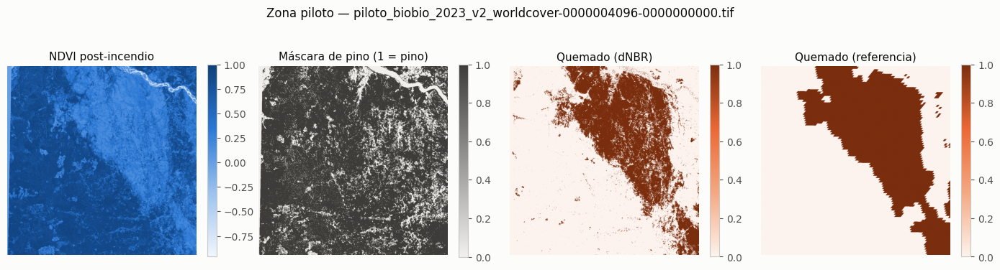

In [12]:
import rasterio
from rasterio.enums import Resampling

def control_calidad(path, factor=4):
    with rasterio.open(path) as src:
        if src.count != 13:
            raise ValueError(f"{os.path.basename(path)} tiene {src.count} bandas; se esperaban 13 "
                             "(export de la v2). Vuelve a exportar desde la seccion 1.")
        A = src.read(out_shape=(13, src.height // factor, src.width // factor),
                     resampling=Resampling.nearest)
        info = dict(archivo=os.path.basename(path), alto_px=src.height, ancho_px=src.width,
                    crs=str(src.crs), res_m=round(src.res[0], 1))
    valido = (A[9] != NODATA) & (A[10] != NODATA)
    for st, b in ETAPA_BANDAS.items():
        info[f"sin_dato_{st}_%"] = round(100 * ((A[b] == NODATA).any(0) & valido).sum() / max(valido.sum(), 1), 1)
    pino = valido & (A[10] > 0)
    info["pino_%"] = round(100 * pino.sum() / max(valido.sum(), 1), 1)
    qd, qr = pino & (A[11] > 0), pino & (A[12] > 0)
    info["quemado_dnbr_%pino"] = round(100 * qd.sum() / max(pino.sum(), 1), 1)
    info["quemado_ref_%pino"] = round(100 * qr.sum() / max(pino.sum(), 1), 1)
    info["IoU_dnbr_ref"] = round((qd & qr).sum() / max((qd | qr).sum(), 1), 3)
    return info, A

qc, vistas = [], {}
for t in TIFS:
    info, A = control_calidad(t)
    qc.append(info); vistas[info["archivo"]] = A
QC = pd.DataFrame(qc)
QC.to_csv(os.path.join(RUN_DIR, "control_calidad_raster.csv"), index=False)
display(QC)

# Vista rapida del archivo con mas pino
nombre = QC.sort_values("pino_%", ascending=False)["archivo"].iloc[0]
A = vistas[nombre].astype(np.float32)
A[A == NODATA] = np.nan
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
paneles = [(A[6] / 1e4, "NDVI post-incendio", CMAP_DATO, None), (A[10], "Máscara de pino (1 = pino)", CMAP_MASCARA, (0, 1)),
           (A[11], "Quemado (dNBR)", CMAP_RIESGO, (0, 1)), (A[12], "Quemado (referencia)", CMAP_RIESGO, (0, 1))]
for a_, (img, tit, cm, lim) in zip(ax, paneles):
    im = a_.imshow(img, cmap=cm, vmin=lim[0] if lim else None, vmax=lim[1] if lim else None)
    a_.set_title(tit); a_.axis("off")
    plt.colorbar(im, ax=a_, fraction=0.046)
fig.suptitle(f"Zona piloto — {nombre}", y=1.02)
plt.tight_layout(); guardar(fig, "01_zona_piloto"); plt.show()
del vistas

## 3. Parches 64×64 con split espacial

- La zona se divide en bloques de 8×8 parches (~5 km); cada bloque completo va a train (70 %), val (15 %) o test (15 %).
- **Train** usa paso 32 px (parches solapados, ~4× más muestras). Un parche solapado nunca cruza el borde de su bloque, así que no hay fuga hacia val/test. **Val y test** usan paso 64 (sin solape).
- Por cada ventana con ≥ `PINO_MIN` de pino se guardan:
  - `preV` y `preO` (pre-incendio, verano y otoño 2022), solo si la ventana está sana según **ambas** etiquetas.
  - `post` (otoño 2023), siempre, con su fracción quemada según dNBR y según la referencia. La etiqueta se decide después (sección 5), así cada experimento puede elegir `etiqueta="dnbr"` o `"ref"`.

In [13]:
def asignar_split(tile, bf, bc):
    h = zlib.crc32(f"{tile}_{bf}_{bc}".encode()) % 100
    return "train" if h < 70 else ("val" if h < 85 else "test")

def procesar_tile(path):
    tile = os.path.splitext(os.path.basename(path))[0]
    with rasterio.open(path) as src:
        A = src.read()                     # (13, H, W) int16, todo en memoria (~440 MB por tile de 4096)
    H, W = A.shape[1:]
    lado = BLOQUE * P
    out = {k: [] for k in ["X", "stage", "split", "tile", "fila", "col", "frac_dnbr", "frac_ref", "solapado"]}
    def agregar(x, st, sp, r, c, fd, fr, sol):
        for k, v in zip(out, [x, st, sp, tile, r, c, fd, fr, sol]):
            out[k].append(v)
    for r in range(0, H - P + 1, STRIDE_TRAIN):
        for c in range(0, W - P + 1, STRIDE_TRAIN):
            en_grilla = (r % P == 0) and (c % P == 0)
            sp = asignar_split(tile, r // lado, c // lado)
            if not en_grilla:
                if sp != "train":
                    continue
                if (r % lado) > lado - P or (c % lado) > lado - P:
                    continue                   # el parche solapado cruzaria a otro bloque
            w = A[:, r:r + P, c:c + P]
            if (w[9:13] == NODATA).any():
                continue
            if (w[10] > 0).mean() < PINO_MIN:
                continue
            fd, fr = float((w[11] > 0).mean()), float((w[12] > 0).mean())
            if fd <= QUEMADO_MAX_SANO and fr <= QUEMADO_MAX_SANO:
                for st in ("preV", "preO"):
                    b = w[ETAPA_BANDAS[st]]
                    if not (b == NODATA).any():
                        agregar(np.concatenate([b, w[9:10]]), st, sp, r, c, fd, fr, not en_grilla)
            if en_grilla:
                b = w[ETAPA_BANDAS["post"]]
                if not (b == NODATA).any():
                    agregar(np.concatenate([b, w[9:10]]), "post", sp, r, c, fd, fr, False)
    del A
    return out

def crear_parches():
    partes = []
    for t in TIFS:
        t0 = time.time(); partes.append(procesar_tile(t))
        print(f"  {os.path.basename(t)}: {len(partes[-1]['X'])} muestras ({time.time() - t0:.0f} s)")
    D = {}
    for k in partes[0]:
        vals = [v for p in partes for v in p[k]]
        if k == "X":
            if not vals:
                raise RuntimeError("0 parches validos: revisa PINO_MIN, la mascara de pino o las nubes (seccion 2).")
            D[k] = np.stack(vals).astype(np.int16)
        else:
            D[k] = np.array(vals)
    np.savez(os.path.join(OUT_DIR, "parches.npz"), **D)
    return len(D["X"])

ruta_npz = os.path.join(OUT_DIR, "parches.npz")
if REHACER_PARCHES or not os.path.exists(ruta_npz):
    print("Muestras creadas:", crear_parches())
else:
    print("Reutilizando", ruta_npz)

D = dict(np.load(ruta_npz))
if "frac_ref" not in D:
    raise ValueError("parches.npz es de la v1. Pon REHACER_PARCHES = True y vuelve a ejecutar.")
HUELLA = f"{len(D['X'])}-{int(D['frac_ref'].sum() * 1000)}-{int(D['frac_dnbr'].sum() * 1000)}"
print("Huella del dataset:", HUELLA, "| memoria X:", round(D["X"].nbytes / 1e9, 2), "GB")

  piloto_biobio_2023_v2_worldcover-0000000000-0000000000.tif: 9443 muestras (4 s)
  piloto_biobio_2023_v2_worldcover-0000000000-0000004096.tif: 3232 muestras (3 s)
  piloto_biobio_2023_v2_worldcover-0000004096-0000000000.tif: 11232 muestras (4 s)
  piloto_biobio_2023_v2_worldcover-0000004096-0000004096.tif: 2804 muestras (3 s)
  piloto_biobio_2023_v2_worldcover-0000008192-0000000000.tif: 2734 muestras (1 s)
  piloto_biobio_2023_v2_worldcover-0000008192-0000004096.tif: 211 muestras (1 s)
Muestras creadas: 29656
Huella del dataset: 29656-1849282-1493920 | memoria X: 0.97 GB


## 4. Exploración del dataset

,etapa,split,total,solapados,sano_dnbr,quemado_dnbr,ambiguo_dnbr,sano_ref,quemado_ref,ambiguo_ref
0,preV,train,10188,7292,,,,,,
1,preV,val,669,0,,,,,,
2,preV,test,564,0,,,,,,
3,preO,train,10188,7292,,,,,,
4,preO,val,669,0,,,,,,
5,preO,test,564,0,,,,,,
6,post,train,4660,0,2896.0,946.0,818.0,2896.0,1191.0,573.0
7,post,val,1040,0,669.0,172.0,199.0,669.0,249.0,122.0
8,post,test,1114,0,564.0,312.0,238.0,564.0,409.0,141.0


Acuerdo dNBR vs referencia en parches post con ambas etiquetas definidas: 100.0 %


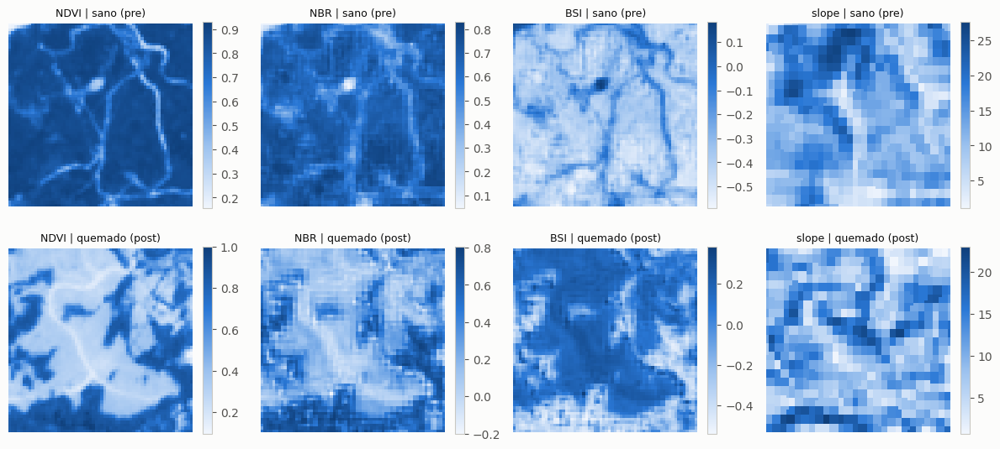

In [14]:
def etiquetas(D, etiqueta):
    # 0 = sano (ambas fuentes <= QUEMADO_MAX_SANO), 1 = quemado segun la fuente elegida, -1 = ambiguo
    fsel = D["frac_dnbr"] if etiqueta == "dnbr" else D["frac_ref"]
    y = np.full(len(fsel), -1, np.int64)
    y[(D["frac_dnbr"] <= QUEMADO_MAX_SANO) & (D["frac_ref"] <= QUEMADO_MAX_SANO)] = 0
    y[fsel >= QUEMADO_MIN_QUEMADO] = 1
    return y

filas = []
for st in ["preV", "preO", "post"]:
    for sp in ["train", "val", "test"]:
        m = (D["stage"] == st) & (D["split"] == sp)
        fila = dict(etapa=st, split=sp, total=int(m.sum()), solapados=int((m & D["solapado"]).sum()))
        if st == "post":
            for et in ["dnbr", "ref"]:
                y = etiquetas(D, et)[m]
                fila[f"sano_{et}"] = int((y == 0).sum()); fila[f"quemado_{et}"] = int((y == 1).sum())
                fila[f"ambiguo_{et}"] = int((y == -1).sum())
        filas.append(fila)
CONTEOS = pd.DataFrame(filas).fillna("")
CONTEOS.to_csv(os.path.join(RUN_DIR, "conteos_dataset.csv"), index=False)
display(CONTEOS)

# Acuerdo entre etiquetas en parches post
mp = D["stage"] == "post"
yd, yr = etiquetas(D, "dnbr")[mp], etiquetas(D, "ref")[mp]
both = (yd >= 0) & (yr >= 0)
if both.any():
    print(f"Acuerdo dNBR vs referencia en parches post con ambas etiquetas definidas: {100 * (yd[both] == yr[both]).mean():.1f} %")

# Un parche sano (preV) y uno quemado (post) — 4 canales en unidades reales
y_b = etiquetas(D, BASE["etiqueta"])
i_s = np.where(D["stage"] == "preV")[0][0]
q = np.where((D["stage"] == "post") & (y_b == 1))[0]
fig, ax = plt.subplots(2, 4, figsize=(12, 5.6))
for f_i, (idx, tit) in enumerate([(i_s, "sano (pre)"), (q[0] if len(q) else i_s, "quemado (post)")]):
    for k, nom in enumerate(CANALES):
        im = ax[f_i, k].imshow(D["X"][idx, k] / ESCALA[k], cmap=CMAP_DATO)
        ax[f_i, k].set_title(f"{nom} | {tit}", fontsize=9); ax[f_i, k].axis("off")
        plt.colorbar(im, ax=ax[f_i, k], fraction=0.046)
plt.tight_layout(); guardar(fig, "02_parches_ejemplo"); plt.show()

## 5. Dataset, DataLoader, VAE y entrenamiento

- **Normalización por experimento:** media y desviación de cada canal se calculan **solo con el train** de la etapa elegida.
- **Métricas nuevas por época:** KL, β efectivo (warm-up) y **unidades latentes activas** (dimensiones de μ con varianza > 0,01 en validación; si caen a ~0 hay colapso posterior).
- **Selección de modelo:** mejor época según error de reconstrucción en validación **sana** (nunca con AUROC ni con test).
- **Estabilidad:** si la pérdida se vuelve NaN/inf, el entrenamiento se detiene y queda registrado.

In [15]:
class ParchesDataset(Dataset):
    def __init__(self, D, idx, ch, mean, std, y, aumentar=False):
        X = D["X"][idx][:, ch].astype(np.float32) / ESCALA[ch][None, :, None, None]
        self.X = (X - mean[None, :, None, None]) / std[None, :, None, None]
        self.y = y[idx]
        self.aumentar = aumentar
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i])
        if self.aumentar:
            if torch.rand(1) < 0.5: x = torch.flip(x, [2])
            if torch.rand(1) < 0.5: x = torch.flip(x, [1])
        return x, int(self.y[i])

def hacer_loaders(D, cfg):
    ch = [CANALES.index(c) for c in cfg["canales"]]
    y = etiquetas(D, cfg["etiqueta"])
    st, sp, sol, et = D["stage"], D["split"], D["solapado"], cfg["etapa_train"]
    sel = {
        "train":     (sp == "train") & (st == et) & (cfg["solapados"] | ~sol),
        "val":       (sp == "val") & (st == et),
        "pre_test":  (sp == "test") & (st == et),
        "eval_val":  (sp == "val") & (st == "post") & (y >= 0),
        "eval_test": (sp == "test") & (st == "post") & (y >= 0),
    }
    itr = np.where(sel["train"])[0]
    Xtr = D["X"][itr][:, ch].astype(np.float32) / ESCALA[ch][None, :, None, None]
    mean, std = Xtr.mean(axis=(0, 2, 3)), Xtr.std(axis=(0, 2, 3)) + 1e-6
    del Xtr
    L = {k: DataLoader(ParchesDataset(D, np.where(m)[0], ch, mean, std, y, aumentar=(k == "train")),
                       batch_size=cfg["bs"], shuffle=(k == "train"), num_workers=0,
                       pin_memory=(DEV == "cuda"))
         for k, m in sel.items()}
    return L, dict(mean=mean.tolist(), std=std.tolist(), canales=cfg["canales"])

class VAE(nn.Module):
    def __init__(self, in_ch=4, z_dim=64, base=32, determinista=False):
        super().__init__()
        c = base
        self.determinista = determinista
        self.enc = nn.Sequential(
            nn.Conv2d(in_ch, c, 4, 2, 1), nn.BatchNorm2d(c), nn.LeakyReLU(0.2),           # 32
            nn.Conv2d(c, 2*c, 4, 2, 1), nn.BatchNorm2d(2*c), nn.LeakyReLU(0.2),           # 16
            nn.Conv2d(2*c, 4*c, 4, 2, 1), nn.BatchNorm2d(4*c), nn.LeakyReLU(0.2),         # 8
            nn.Conv2d(4*c, 8*c, 4, 2, 1), nn.BatchNorm2d(8*c), nn.LeakyReLU(0.2))         # 4
        self.fc_mu = nn.Linear(8*c*16, z_dim)
        self.fc_lv = nn.Linear(8*c*16, z_dim)
        self.fc_dec = nn.Linear(z_dim, 8*c*16)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(8*c, 4*c, 4, 2, 1), nn.BatchNorm2d(4*c), nn.ReLU(),
            nn.ConvTranspose2d(4*c, 2*c, 4, 2, 1), nn.BatchNorm2d(2*c), nn.ReLU(),
            nn.ConvTranspose2d(2*c, c, 4, 2, 1), nn.BatchNorm2d(c), nn.ReLU(),
            nn.ConvTranspose2d(c, in_ch, 4, 2, 1))
        self.c8 = 8 * c
    def encode(self, x):
        h = self.enc(x).flatten(1)
        return self.fc_mu(h), self.fc_lv(h).clamp(-10, 10)
    def decode(self, z):
        return self.dec(self.fc_dec(z).view(-1, self.c8, 4, 4))
    def forward(self, x):
        mu, lv = self.encode(x)
        if self.training and not self.determinista:
            z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
        else:
            z = mu
        return self.decode(z), mu, lv

def perdida(x, xr, mu, lv, beta):
    rec = F.mse_loss(xr, x, reduction="none").flatten(1).mean(1)
    kl = -0.5 * (1 + lv - mu.pow(2) - lv.exp()).sum(1) / x[0].numel()   # KL por dimension de entrada
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()

@torch.no_grad()
def errores(model, loader):
    model.eval(); e, ys = [], []
    for x, y in loader:
        x = x.to(DEV); xr, _, _ = model(x)
        e.append(F.mse_loss(xr, x, reduction="none").flatten(1).mean(1).cpu()); ys.append(y)
    if not e:
        return np.zeros(0), np.zeros(0, np.int64)
    return torch.cat(e).numpy(), torch.cat(ys).numpy()

def auroc(model, loader):
    e, y = errores(model, loader)
    return (float(roc_auc_score(y, e)) if len(np.unique(y)) > 1 else float("nan")), e, y

@torch.no_grad()
def unidades_activas(model, loader, umbral=0.01):
    model.eval(); mus = []
    for x, _ in loader:
        mus.append(model.encode(x.to(DEV))[0].cpu())
    return int((torch.cat(mus).var(0) > umbral).sum()) if mus else 0

def entrenar(nombre, cambios=None, verbose=True):
    cfg = {**BASE, **(cambios or {})}
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
    L, stats = hacer_loaders(D, cfg)
    model = VAE(len(cfg["canales"]), cfg["z"], determinista=(cfg["beta"] == 0)).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    hist, mejor, mejor_ep, mejor_estado, sin_mejora, estado = [], float("inf"), 0, None, 0, "ok"
    t0 = time.time()
    for ep in range(1, cfg["epochs"] + 1):
        beta_ep = cfg["beta"] * (min(1.0, ep / cfg["warmup"]) if cfg["warmup"] else 1.0)
        model.train(); tot = rec_t = kl_t = n = 0
        for x, _ in L["train"]:
            x = x.to(DEV, non_blocking=True)
            xr, mu, lv = model(x)
            loss, rec, kl = perdida(x, xr, mu, lv, beta_ep)
            if not torch.isfinite(loss):
                estado = f"diverge_ep{ep}"; break
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            b = len(x); n += b
            tot += loss.item() * b; rec_t += rec.item() * b; kl_t += kl.item() * b
        if estado != "ok":
            print(f"[{nombre}] perdida no finita en la epoca {ep}: se detiene"); break
        val_rec = float(errores(model, L["val"])[0].mean())
        au_val = auroc(model, L["eval_val"])[0]
        ua = unidades_activas(model, L["val"])
        hist.append(dict(epoch=ep, beta=beta_ep, train_loss=tot / n, train_rec=rec_t / n,
                         train_kl=kl_t / n, val_rec=val_rec, auroc_val=au_val, unidades_activas=ua))
        if val_rec < mejor - 1e-5:
            mejor, mejor_ep, sin_mejora = val_rec, ep, 0
            mejor_estado = copy.deepcopy(model.state_dict())
        else:
            sin_mejora += 1
        if verbose and (ep == 1 or ep % 5 == 0 or ep == cfg["epochs"]):
            print(f"[{nombre}] ep {ep:3d} | rec {rec_t/n:.4f} kl {kl_t/n:.4f} | val_rec {val_rec:.4f} "
                  f"| AUROC(val) {au_val:.3f} | activas {ua}/{cfg['z']}")
        if cfg["paciencia"] and sin_mejora >= cfg["paciencia"]:
            if verbose: print(f"[{nombre}] early stopping en la epoca {ep} (mejor: {mejor_ep})")
            break
    if mejor_estado is not None:
        model.load_state_dict(mejor_estado)
    torch.save(model.state_dict(), os.path.join(RUN_DIR, f"{nombre}.pt"))
    au_t, e_t, y_t = auroc(model, L["eval_test"])
    au_v = auroc(model, L["eval_val"])[0]
    e_pre = errores(model, L["pre_test"])[0]
    e_ps = e_t[y_t == 0]
    au_est = (float(roc_auc_score(np.r_[np.zeros(len(e_pre)), np.ones(len(e_ps))], np.r_[e_pre, e_ps]))
              if len(e_pre) and len(e_ps) else float("nan"))
    res = dict(nombre=nombre, estado=estado, auroc_val=au_v, auroc_test=au_t, auroc_estacional=au_est,
               unidades_activas=unidades_activas(model, L["val"]),
               err_sano=float(e_ps.mean()) if len(e_ps) else float("nan"),
               err_quemado=float(e_t[y_t == 1].mean()) if (y_t == 1).any() else float("nan"),
               err_pre_test=float(e_pre.mean()) if len(e_pre) else float("nan"),
               mejor_epoca=mejor_ep, epocas=len(hist), n_train=len(L["train"].dataset),
               n_test=int(len(y_t)), segundos=round(time.time() - t0, 1), huella=HUELLA,
               **{k: (",".join(v) if isinstance(v, list) else v) for k, v in cfg.items()})
    json.dump(dict(resumen=res, historial=hist, stats=stats, cfg=cfg),
              open(os.path.join(RUN_DIR, f"{nombre}.json"), "w"), indent=2, default=str)
    return model, L, res, hist

def correr(nombre, cambios=None):
    # Entrena, o reutiliza el resultado si ya se corrio con este mismo dataset.
    ruta = os.path.join(RUN_DIR, f"{nombre}.json")
    if os.path.exists(ruta) and not REPETIR_EXPERIMENTOS:
        J = json.load(open(ruta))
        if J["resumen"].get("huella") == HUELLA:
            print(f"[{nombre}] reutilizado"); return J["resumen"], J["historial"]
    _, _, res, hist = entrenar(nombre, cambios, verbose=False)
    print(f"[{nombre}] AUROC val {res['auroc_val']:.3f} | test {res['auroc_test']:.3f} | "
          f"activas {res['unidades_activas']} | {res['epocas']} ep | {res['segundos']} s")
    return res, hist

def cargar_modelo(nombre):
    J = json.load(open(os.path.join(RUN_DIR, f"{nombre}.json")))
    cfg = J["cfg"]
    m = VAE(len(cfg["canales"]), cfg["z"], determinista=(cfg["beta"] == 0)).to(DEV)
    m.load_state_dict(torch.load(os.path.join(RUN_DIR, f"{nombre}.pt"), map_location=DEV, weights_only=True))
    return m.eval(), cfg, J["stats"]

## 6. E1 — Baseline

VAE con la configuración `BASE`. Evaluación completa: curvas, ROC, distribución del puntaje, reconstrucciones y chequeo estacional.

In [16]:
model_e1, L_e1, RES_E1, HIST_E1 = entrenar("E1_base")
print({k: len(v.dataset) for k, v in L_e1.items()})

[E1_base] ep   1 | rec 0.4713 kl 0.0156 | val_rec 0.3243 | AUROC(val) 0.925 | activas 64/64
[E1_base] ep   5 | rec 0.2375 kl 0.0142 | val_rec 0.2301 | AUROC(val) 0.950 | activas 64/64
[E1_base] ep  10 | rec 0.2291 kl 0.0135 | val_rec 0.2142 | AUROC(val) 0.837 | activas 64/64
[E1_base] ep  15 | rec 0.2249 kl 0.0132 | val_rec 0.2102 | AUROC(val) 0.847 | activas 64/64
[E1_base] ep  20 | rec 0.2194 kl 0.0127 | val_rec 0.2076 | AUROC(val) 0.839 | activas 64/64
[E1_base] ep  25 | rec 0.2162 kl 0.0125 | val_rec 0.2089 | AUROC(val) 0.906 | activas 64/64
[E1_base] ep  30 | rec 0.2148 kl 0.0123 | val_rec 0.2084 | AUROC(val) 0.882 | activas 64/64
[E1_base] ep  35 | rec 0.2133 kl 0.0123 | val_rec 0.2134 | AUROC(val) 0.959 | activas 64/64
[E1_base] ep  40 | rec 0.2106 kl 0.0122 | val_rec 0.2075 | AUROC(val) 0.913 | activas 64/64
[E1_base] ep  45 | rec 0.2091 kl 0.0121 | val_rec 0.2042 | AUROC(val) 0.850 | activas 64/64
[E1_base] ep  50 | rec 0.2088 kl 0.0120 | val_rec 0.2042 | AUROC(val) 0.863 | ac

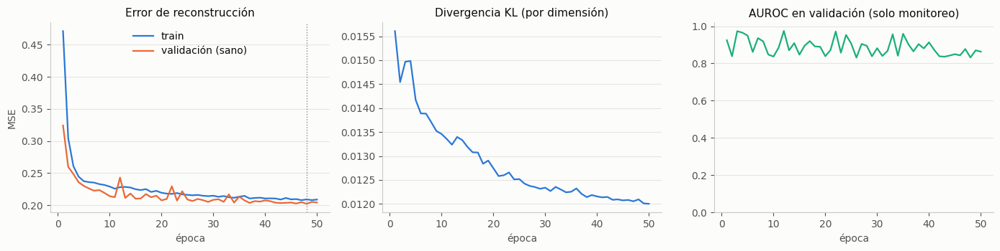

In [17]:
h = pd.DataFrame(HIST_E1)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(h.epoch, h.train_rec, color=AZUL, label="train")
ax[0].plot(h.epoch, h.val_rec, color=NARANJA, label="validación (sano)")
ax[0].axvline(RES_E1["mejor_epoca"], color=GRIS, ls=":", lw=1)
ax[0].set(title="Error de reconstrucción", xlabel="época", ylabel="MSE"); ax[0].legend()
ax[1].plot(h.epoch, h.train_kl, color=AZUL)
ax[1].set(title="Divergencia KL (por dimensión)", xlabel="época")
ax[2].plot(h.epoch, h.auroc_val, color=AQUA)
ax[2].set(title="AUROC en validación (solo monitoreo)", xlabel="época", ylim=(0, 1.02))
plt.tight_layout(); guardar(fig, "03_E1_curvas"); plt.show()

TEST AUROC = 0.806  (sanos=564, quemados=312)


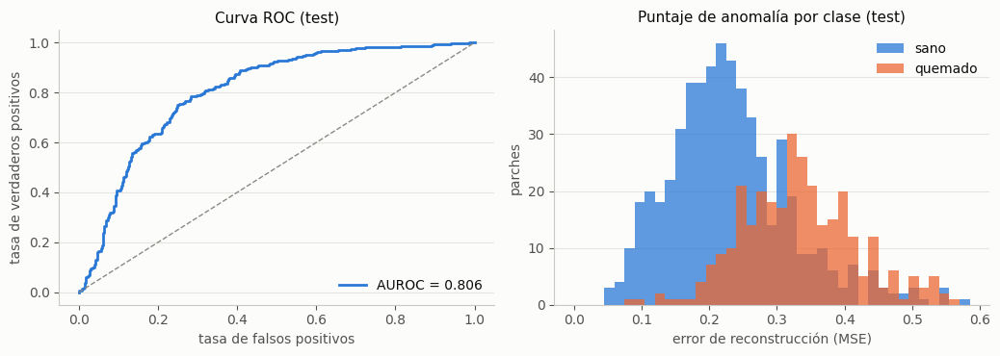

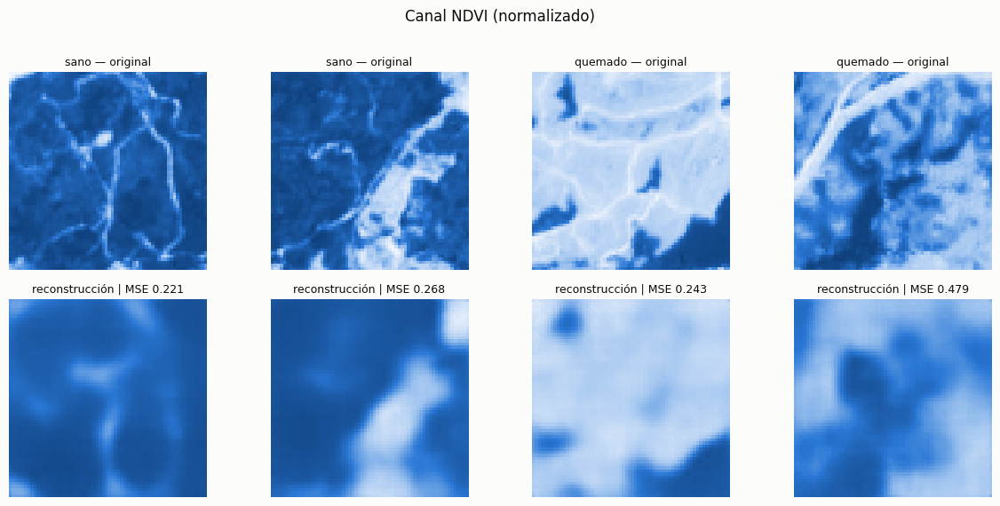

Chequeo estacional: error sano pre-test 0.2138 vs sano post-test 0.2341 | AUROC pre-sano vs post-sano = 0.569 (0.5 = sin sesgo)


In [18]:
au_t, e_t, y_t = auroc(model_e1, L_e1["eval_test"])
print(f"TEST AUROC = {au_t:.3f}  (sanos={int((y_t == 0).sum())}, quemados={int((y_t == 1).sum())})")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
if len(np.unique(y_t)) > 1:
    fpr, tpr, _ = roc_curve(y_t, e_t)
    ax[0].plot(fpr, tpr, color=AZUL, lw=2, label=f"AUROC = {au_t:.3f}")
ax[0].plot([0, 1], [0, 1], "--", color=GRIS, lw=1)
ax[0].set(title="Curva ROC (test)", xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos")
ax[0].legend(loc="lower right")
bins = np.linspace(0, np.percentile(e_t, 99), 40)
ax[1].hist(e_t[y_t == 0], bins=bins, alpha=0.75, color=AZUL, label="sano")
ax[1].hist(e_t[y_t == 1], bins=bins, alpha=0.75, color=NARANJA, label="quemado")
ax[1].set(title="Puntaje de anomalía por clase (test)", xlabel="error de reconstrucción (MSE)", ylabel="parches")
ax[1].legend()
plt.tight_layout(); guardar(fig, "04_E1_roc_histograma"); plt.show()

ds = L_e1["eval_test"].dataset
idx = list(np.where(ds.y == 0)[0][:2]) + list(np.where(ds.y == 1)[0][:2])
if idx:
    fig, ax = plt.subplots(2, len(idx), figsize=(3 * len(idx), 5.6), squeeze=False)
    for j, i in enumerate(idx):
        x = torch.from_numpy(ds.X[i])[None].to(DEV)
        with torch.no_grad(): xr, _, _ = model_e1.eval()(x)
        vmin, vmax = float(x[0, 0].min()), float(x[0, 0].max())
        ax[0, j].imshow(x[0, 0].cpu(), cmap=CMAP_DATO, vmin=vmin, vmax=vmax)
        ax[0, j].set_title(f"{'sano' if ds.y[i] == 0 else 'quemado'} — original", fontsize=9)
        ax[1, j].imshow(xr[0, 0].cpu(), cmap=CMAP_DATO, vmin=vmin, vmax=vmax)
        ax[1, j].set_title(f"reconstrucción | MSE {F.mse_loss(xr, x).item():.3f}", fontsize=9)
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle("Canal NDVI (normalizado)", y=1.01)
    plt.tight_layout(); guardar(fig, "05_E1_reconstrucciones"); plt.show()

print(f"Chequeo estacional: error sano pre-test {RES_E1['err_pre_test']:.4f} vs sano post-test {RES_E1['err_sano']:.4f} "
      f"| AUROC pre-sano vs post-sano = {RES_E1['auroc_estacional']:.3f} (0.5 = sin sesgo)")

## 7. Experimentos E2–E7

Cada experimento cambia **una sola cosa** respecto a E1 y responde una pregunta:

| Exp. | Pregunta | Cambio |
|---|---|---|
| E2 | ¿Hay colapso posterior con β alto? ¿Lo evita el KL warm-up? | β = 1 y 4, con warm-up de 10 épocas |
| E3 | ¿VAE o autoencoder determinista? ¿Qué β conviene? | β ∈ {0 (AE), 0,1, 1, 2, 4} |
| E4 | ¿Se corrige el sobreajuste? | weight decay 1e-4 + early stopping (paciencia 10) |
| E5 | ¿Detecta el incendio o el cambio de estación? | entrenar con otoño 2022 (`preO`) en vez de verano |
| E6 | ¿El AUROC es circular? | etiqueta de referencia; y además sin el canal NBR |
| E7 | ¿Es estable? | la mejor configuración (elegida por AUROC de **validación**) con semillas 1 y 2 |

Los experimentos ya corridos con el mismo dataset se reutilizan; pon `REPETIR_EXPERIMENTOS = True` para forzar.

In [19]:
EXPERIMENTOS = {
    "E3_beta0_AE":       dict(beta=0.0),
    "E3_beta0.1":        dict(beta=0.1),
    "E3_beta1":          dict(beta=1.0),
    "E3_beta2":          dict(beta=2.0),
    "E3_beta4":          dict(beta=4.0),
    "E2_beta1_warmup":   dict(beta=1.0, warmup=10),
    "E2_beta4_warmup":   dict(beta=4.0, warmup=10),
    "E4_regularizado":   dict(wd=1e-4, paciencia=10),
    "E5_pre_otono":      dict(etapa_train="preO"),
    "E6_etiqueta_ref":   dict(etiqueta="ref"),
    "E6_ref_sin_NBR":    dict(etiqueta="ref", canales=["NDVI", "BSI", "slope"]),
}
RES, HIST = {"E1_base": RES_E1}, {"E1_base": HIST_E1}
t0 = time.time()
for nombre, cambios in EXPERIMENTOS.items():
    RES[nombre], HIST[nombre] = correr(nombre, cambios)

# E7: semillas de la mejor configuracion (mismo tipo de etiqueta que la base, elegida por AUROC de VALIDACION)
cand = {k: v for k, v in RES.items() if v["etiqueta"] == BASE["etiqueta"] and v["estado"] == "ok"}
MEJOR = max(cand, key=lambda k: np.nan_to_num(cand[k]["auroc_val"], nan=-1))
cambios_mejor = {**EXPERIMENTOS.get(MEJOR, {})}
print("\nMejor configuracion por AUROC de validacion:", MEJOR)
for s in (1, 2):
    nombre = f"E7_{MEJOR}_seed{s}"
    RES[nombre], HIST[nombre] = correr(nombre, {**cambios_mejor, "seed": s})
print(f"\nTiempo total de experimentos: {(time.time() - t0) / 60:.1f} min")

TABLA = pd.DataFrame(RES.values())
TABLA.to_csv(os.path.join(RUN_DIR, "experimentos.csv"), index=False)
cols = ["nombre", "beta", "warmup", "wd", "paciencia", "etapa_train", "etiqueta", "canales",
        "auroc_val", "auroc_test", "auroc_estacional", "unidades_activas", "mejor_epoca", "epocas", "estado"]
display(TABLA[cols].round(3))

[E3_beta0_AE] reutilizado
[E3_beta0.1] reutilizado
[E3_beta1] reutilizado
[E3_beta2] reutilizado
[E3_beta4] reutilizado
[E2_beta1_warmup] reutilizado
[E2_beta4_warmup] reutilizado
[E4_regularizado] reutilizado
[E5_pre_otono] reutilizado
[E6_etiqueta_ref] reutilizado
[E6_ref_sin_NBR] reutilizado

Mejor configuracion por AUROC de validacion: E3_beta0.1
[E7_E3_beta0.1_seed1] reutilizado
[E7_E3_beta0.1_seed2] reutilizado

Tiempo total de experimentos: 0.0 min


,nombre,beta,warmup,wd,paciencia,etapa_train,etiqueta,canales,auroc_val,auroc_test,auroc_estacional,unidades_activas,mejor_epoca,epocas,estado
0,E1_base,0.5,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.832,0.806,0.569,64,48,50,ok
1,E3_beta0_AE,0.0,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.836,0.821,0.561,64,42,50,ok
2,E3_beta0.1,0.1,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.852,0.834,0.565,64,37,50,ok
3,E3_beta1,1.0,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.831,0.804,0.570,64,48,50,ok
4,E3_beta2,2.0,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.835,0.808,0.569,64,48,50,ok
5,E3_beta4,4.0,0,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.824,0.778,0.565,64,43,50,ok
6,E2_beta1_warmup,1.0,10,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.843,0.821,0.564,64,37,50,ok
7,E2_beta4_warmup,4.0,10,0.0,NaN,preV,dnbr,"NDVI,NBR,BSI,slope",0.828,0.790,0.567,64,43,50,ok
8,E4_regularizado,0.5,0,0.0,10.0,preV,dnbr,"NDVI,NBR,BSI,slope",0.830,0.801,0.567,64,48,50,ok
9,E5_pre_otono,0.5,0,0.0,NaN,preO,dnbr,"NDVI,NBR,BSI,slope",0.836,0.799,0.542,64,38,50,ok


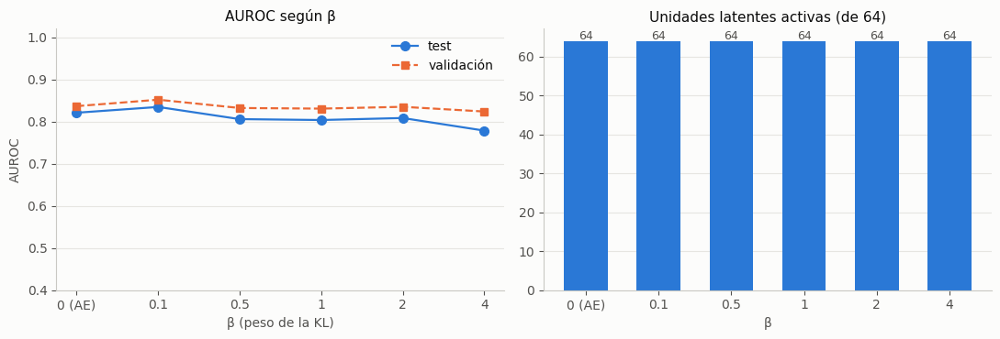

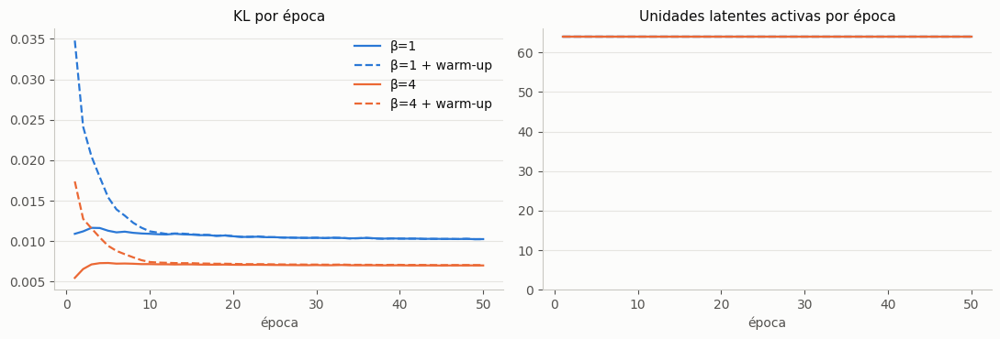

In [20]:
# E2/E3 — efecto de beta: AUROC y unidades latentes activas
orden = [("E3_beta0_AE", "0 (AE)"), ("E3_beta0.1", "0.1"), ("E1_base", "0.5"),
         ("E3_beta1", "1"), ("E3_beta2", "2"), ("E3_beta4", "4")]
etq = [e for _, e in orden]; xs = np.arange(len(orden))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(xs, [RES[k]["auroc_test"] for k, _ in orden], "o-", color=AZUL, ms=7, label="test")
ax[0].plot(xs, [RES[k]["auroc_val"] for k, _ in orden], "s--", color=NARANJA, ms=6, label="validación")
v_au = [RES[k][m] for k, _ in orden for m in ("auroc_test", "auroc_val")]
ax[0].set(title="AUROC según β", xlabel="β (peso de la KL)", ylabel="AUROC", xticks=xs, xticklabels=etq,
          ylim=(min(0.4, np.nanmin(v_au) - 0.05), 1.02))
ax[0].legend()
ax[1].bar(xs, [RES[k]["unidades_activas"] for k, _ in orden], color=AZUL, width=0.6)
ax[1].set(title="Unidades latentes activas (de %d)" % BASE["z"], xlabel="β", xticks=xs, xticklabels=etq)
for x_, k in zip(xs, [k for k, _ in orden]):
    ax[1].text(x_, RES[k]["unidades_activas"] + 0.5, str(RES[k]["unidades_activas"]), ha="center", fontsize=9, color="#52514e")
plt.tight_layout(); guardar(fig, "06_E3_beta"); plt.show()

# E2 — warm-up: KL y unidades activas por epoca
pares = [("E3_beta1", "β=1", AZUL, "-"), ("E2_beta1_warmup", "β=1 + warm-up", AZUL, "--"),
         ("E3_beta4", "β=4", NARANJA, "-"), ("E2_beta4_warmup", "β=4 + warm-up", NARANJA, "--")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, lab, col, ls in pares:
    hh = pd.DataFrame(HIST[k])
    ax[0].plot(hh.epoch, hh.train_kl, color=col, ls=ls, label=lab)
    ax[1].plot(hh.epoch, hh.unidades_activas, color=col, ls=ls, label=lab)
ax[0].set(title="KL por época", xlabel="época"); ax[0].legend()
ax[1].set(title="Unidades latentes activas por época", xlabel="época", ylim=(0, BASE["z"] + 2))
plt.tight_layout(); guardar(fig, "07_E2_warmup"); plt.show()

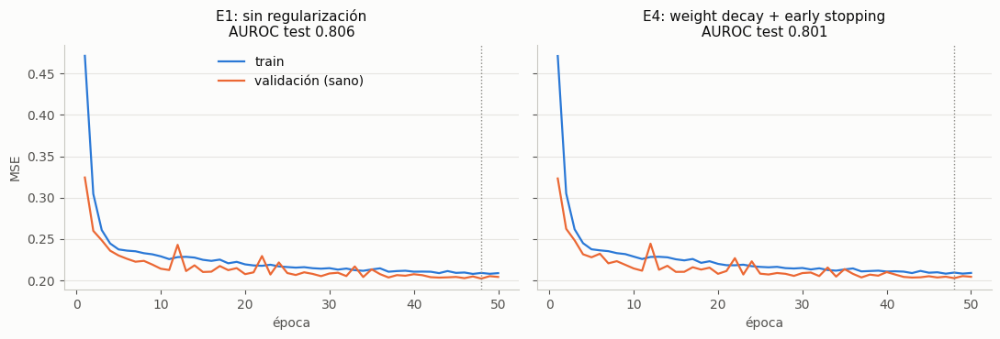

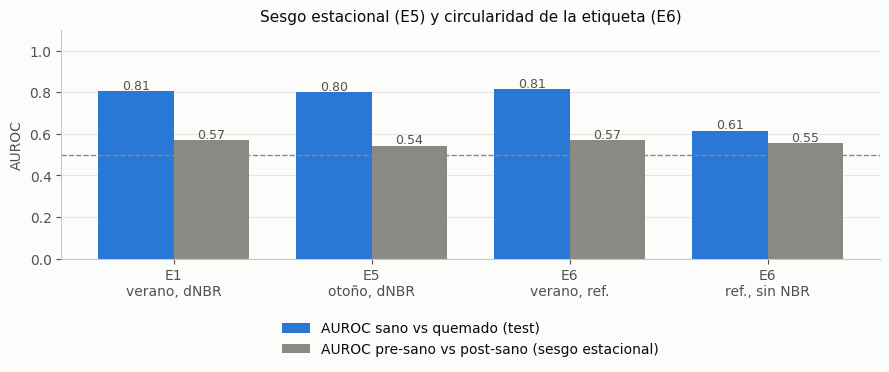

E7 — E3_beta0.1: AUROC test = 0.832 ± 0.002 (3 semillas: [0.834, 0.831, 0.831])


In [21]:
# E4 — sobreajuste: curvas train/val sin y con regularizacion
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, k, tit in [(ax[0], "E1_base", "E1: sin regularización"), (ax[1], "E4_regularizado", "E4: weight decay + early stopping")]:
    hh = pd.DataFrame(HIST[k])
    a_.plot(hh.epoch, hh.train_rec, color=AZUL, label="train")
    a_.plot(hh.epoch, hh.val_rec, color=NARANJA, label="validación (sano)")
    a_.axvline(RES[k]["mejor_epoca"], color=GRIS, ls=":", lw=1)
    a_.set(title=f"{tit}\nAUROC test {RES[k]['auroc_test']:.3f}", xlabel="época")
ax[0].set_ylabel("MSE"); ax[0].legend()
plt.tight_layout(); guardar(fig, "08_E4_sobreajuste"); plt.show()

# E5 y E6 — sesgo estacional y circularidad
grupos = [("E1_base", "E1\nverano, dNBR"), ("E5_pre_otono", "E5\notoño, dNBR"),
          ("E6_etiqueta_ref", "E6\nverano, ref."), ("E6_ref_sin_NBR", "E6\nref., sin NBR")]
xs = np.arange(len(grupos)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(xs - w/2, [RES[k]["auroc_test"] for k, _ in grupos], w, color=AZUL, label="AUROC sano vs quemado (test)")
ax.bar(xs + w/2, [RES[k]["auroc_estacional"] for k, _ in grupos], w, color=GRIS, label="AUROC pre-sano vs post-sano (sesgo estacional)")
for x_, k in zip(xs, [k for k, _ in grupos]):
    ax.text(x_ - w/2, RES[k]["auroc_test"] + 0.01, f"{RES[k]['auroc_test']:.2f}", ha="center", fontsize=9, color="#52514e")
    ax.text(x_ + w/2, RES[k]["auroc_estacional"] + 0.01, f"{RES[k]['auroc_estacional']:.2f}", ha="center", fontsize=9, color="#52514e")
ax.axhline(0.5, color=GRIS, ls="--", lw=1)
ax.set(ylim=(0, 1.1), xticks=xs, xticklabels=[g for _, g in grupos], ylabel="AUROC",
       title="Sesgo estacional (E5) y circularidad de la etiqueta (E6)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1)
plt.tight_layout(); guardar(fig, "09_E5_E6"); plt.show()

# E7 — estabilidad entre semillas
semillas = [MEJOR] + [f"E7_{MEJOR}_seed{s}" for s in (1, 2)]
v = np.array([RES[k]["auroc_test"] for k in semillas])
print(f"E7 — {MEJOR}: AUROC test = {v.mean():.3f} ± {v.std(ddof=1):.3f} (3 semillas: {np.round(v, 3).tolist()})")

## 8. Mapa de puntaje de anomalía (objetivo específico 3)

Puntúa **todos** los parches post-incendio (incluidos los ambiguos y los de train: el modelo solo vio parches *pre*) con el modelo `MEJOR`, y los dibuja en su posición. A la derecha, la fracción quemada según la referencia, para comparar visualmente.

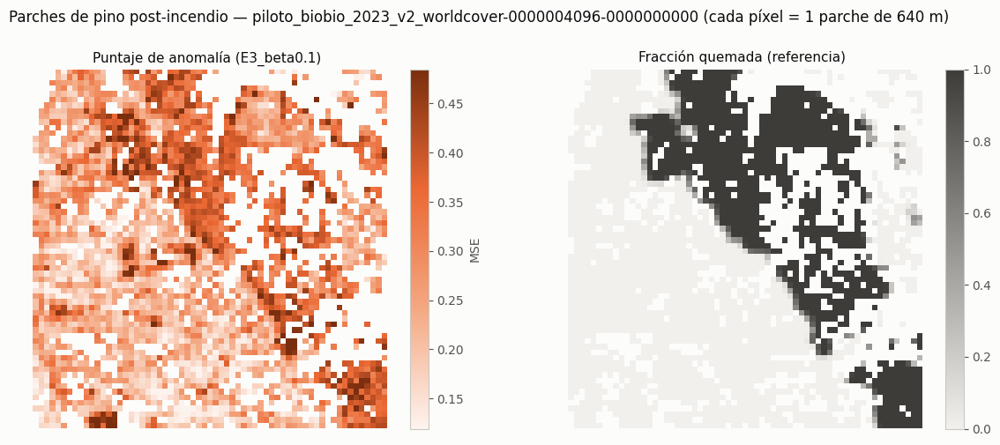

Correlación de Spearman puntaje vs fracción quemada (todos los parches post): 0.544


In [22]:
@torch.no_grad()
def puntajes(model, stats, idx, bs=256):
    ch = [CANALES.index(c) for c in stats["canales"]]
    mean, std = np.array(stats["mean"], np.float32), np.array(stats["std"], np.float32)
    out = []
    for i in range(0, len(idx), bs):
        X = D["X"][idx[i:i + bs]][:, ch].astype(np.float32) / ESCALA[ch][None, :, None, None]
        x = torch.from_numpy((X - mean[None, :, None, None]) / std[None, :, None, None]).to(DEV)
        xr, _, _ = model(x)
        out.append(F.mse_loss(xr, x, reduction="none").flatten(1).mean(1).cpu().numpy())
    return np.concatenate(out) if out else np.zeros(0)

model_m, cfg_m, stats_m = cargar_modelo(MEJOR)
ip = np.where(D["stage"] == "post")[0]
score = puntajes(model_m, stats_m, ip)
tile_top = pd.Series(D["tile"][ip]).value_counts().index[0]
sel = D["tile"][ip] == tile_top
f_, c_ = D["fila"][ip][sel] // P, D["col"][ip][sel] // P
M_s = np.full((f_.max() + 1, c_.max() + 1), np.nan); M_s[f_, c_] = score[sel]
M_q = np.full_like(M_s, np.nan); M_q[f_, c_] = D["frac_ref"][ip][sel]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
im0 = ax[0].imshow(M_s, cmap=CMAP_RIESGO, vmin=np.nanpercentile(M_s, 2), vmax=np.nanpercentile(M_s, 98))
ax[0].set_title(f"Puntaje de anomalía ({MEJOR})"); plt.colorbar(im0, ax=ax[0], fraction=0.046, label="MSE")
im1 = ax[1].imshow(M_q, cmap=CMAP_MASCARA, vmin=0, vmax=1)
ax[1].set_title("Fracción quemada (referencia)"); plt.colorbar(im1, ax=ax[1], fraction=0.046)
for a_ in ax: a_.axis("off")
fig.suptitle(f"Parches de pino post-incendio — {tile_top} (cada píxel = 1 parche de 640 m)", y=1.0)
plt.tight_layout(); guardar(fig, "10_mapa_puntaje"); plt.show()

ok = ~np.isnan(score)
print(f"Correlación de Spearman puntaje vs fracción quemada (todos los parches post): "
      f"{pd.Series(score[ok]).corr(pd.Series(D['frac_ref'][ip][ok]), method='spearman'):.3f}")

## 9. Resumen

In [23]:
res_cols = ["nombre", "auroc_val", "auroc_test", "auroc_estacional", "unidades_activas", "epocas", "segundos"]
display(TABLA[res_cols].round(3))
print(f"Mejor configuracion (por validacion): {MEJOR}")
print(f"Figuras guardadas en {os.path.abspath(FIG_DIR)}:")
for f in sorted(os.listdir(FIG_DIR)):
    print("  ", f)
if USE_SYNTHETIC:
    print("\nOJO: resultados con datos SINTETICOS. Solo prueban que el pipeline corre; no los uses en la presentacion.")

,nombre,auroc_val,auroc_test,auroc_estacional,unidades_activas,epocas,segundos
0,E1_base,0.832,0.806,0.569,64,50,165.3
1,E3_beta0_AE,0.836,0.821,0.561,64,50,129.1
2,E3_beta0.1,0.852,0.834,0.565,64,50,130.0
3,E3_beta1,0.831,0.804,0.570,64,50,131.6
4,E3_beta2,0.835,0.808,0.569,64,50,131.5
5,E3_beta4,0.824,0.778,0.565,64,50,135.4
6,E2_beta1_warmup,0.843,0.821,0.564,64,50,131.3
7,E2_beta4_warmup,0.828,0.790,0.567,64,50,131.3
8,E4_regularizado,0.830,0.801,0.567,64,50,131.8
9,E5_pre_otono,0.836,0.799,0.542,64,50,131.5


Mejor configuracion (por validacion): E3_beta0.1
Figuras guardadas en c:\Users\mario\Desktop\Generative Deep Learning Proyecto\runs\figs:
   01_zona_piloto.png
   02_parches_ejemplo.png
   03_E1_curvas.png
   04_E1_roc_histograma.png
   05_E1_reconstrucciones.png
   06_E3_beta.png
   07_E2_warmup.png
   08_E4_sobreajuste.png
   09_E5_E6.png
   10_mapa_puntaje.png
   ppt_antes_despues.png
   ppt_estacion.png
   ppt_pendiente_mascara_etiquetas.png
   ppt_zona_archivos.png


### Pendiente para el informe final
- FID: Inception está entrenada con fotos RGB y estos parches son índices espectrales; hay que definir un extractor de características adecuado al dominio antes de reportarlo.
- Correlación del puntaje con pendiente y rotaciones (objetivo exploratorio 5).
- Reemplazar MODIS por perímetros oficiales de CONAF si se consiguen (`FIRE_ASSET`).

,n,archivo,fila_px,col_px,alto_px,ancho_px,alto_km,ancho_km,bandas,crs,lat,lon
0,1,piloto_biobio_2023_v2_worldcover-0000000000-00...,0,0,4096,4096,41.0,41.0,13,EPSG:32718,-37.169 a -36.792,-73.219 a -72.749
1,2,piloto_biobio_2023_v2_worldcover-0000000000-00...,0,4096,4096,3212,41.0,32.1,13,EPSG:32718,-37.161 a -36.785,-72.760 a -72.388
2,3,piloto_biobio_2023_v2_worldcover-0000004096-00...,4096,0,4096,4096,41.0,41.0,13,EPSG:32718,-37.538 a -37.161,-73.210 a -72.738
3,4,piloto_biobio_2023_v2_worldcover-0000004096-00...,4096,4096,4096,3212,41.0,32.1,13,EPSG:32718,-37.530 a -37.154,-72.749 a -72.375
4,5,piloto_biobio_2023_v2_worldcover-0000008192-00...,8192,0,851,4096,8.5,41.0,13,EPSG:32718,-37.615 a -37.530,-73.202 a -72.736
5,6,piloto_biobio_2023_v2_worldcover-0000008192-00...,8192,4096,851,3212,8.5,32.1,13,EPSG:32718,-37.607 a -37.523,-72.738 a -72.372


Bandas de cada archivo:
   1. preV_NDVI
   2. preV_NBR
   3. preV_BSI
   4. preO_NDVI
   5. preO_NBR
   6. preO_BSI
   7. post_NDVI
   8. post_NBR
   9. post_BSI
  10. slope
  11. pine
  12. burned_dnbr
  13. burned_ref


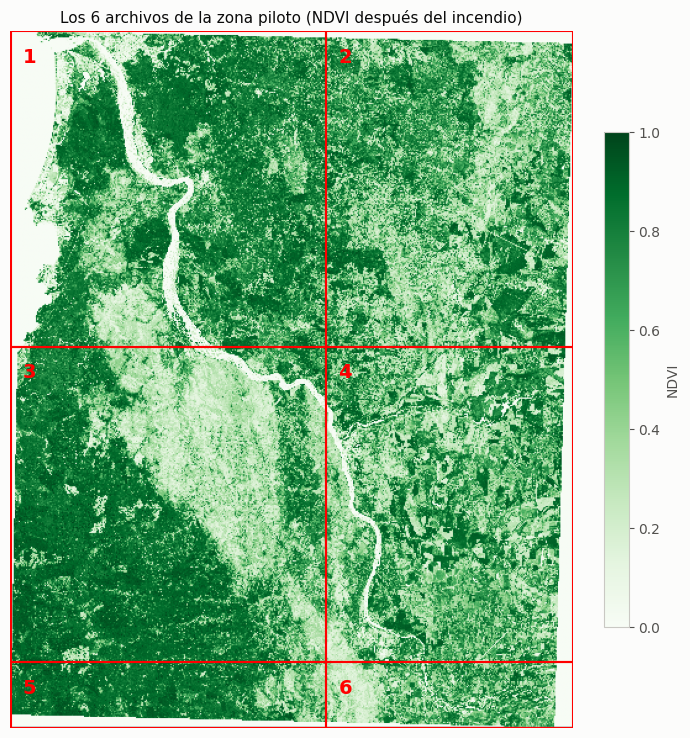

In [24]:
# Ver los 6 archivos que exportó Google Earth Engine y cómo encajan
import glob, os, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds

RAW_DIR = globals().get("RAW_DIR", "./data/raw")
NODATA = globals().get("NODATA", -32768)
BANDAS = globals().get("BANDAS", ["preV_NDVI", "preV_NBR", "preV_BSI", "preO_NDVI", "preO_NBR", "preO_BSI",
                                  "post_NDVI", "post_NBR", "post_BSI", "slope", "pine", "burned_dnbr", "burned_ref"])
F = 16  # se lee 1 de cada 16 píxeles, solo para dibujar rápido

tifs = sorted(glob.glob(os.path.join(RAW_DIR, "*.tif")))
filas = []
for i, path in enumerate(tifs):
    m = re.search(r"-(\d{10})-(\d{10})\.tif$", path)
    r0, c0 = (int(m.group(1)), int(m.group(2))) if m else (0, 0)
    with rasterio.open(path) as src:
        oeste, sur, este, norte = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        filas.append(dict(n=i + 1, archivo=os.path.basename(path), fila_px=r0, col_px=c0,
                          alto_px=src.height, ancho_px=src.width,
                          alto_km=round(src.height * src.res[1] / 1000, 1),
                          ancho_km=round(src.width * src.res[0] / 1000, 1),
                          bandas=src.count, crs=str(src.crs),
                          lat=f"{sur:.3f} a {norte:.3f}", lon=f"{oeste:.3f} a {este:.3f}"))
tabla = pd.DataFrame(filas)
display(tabla)
print("Bandas de cada archivo:")
for k, b in enumerate(BANDAS, 1):
    print(f"  {k:2d}. {b}")

# Mapa: los 6 pedazos en su lugar, con el NDVI después del incendio (banda 7)
H = max(f["fila_px"] + f["alto_px"] for f in filas)
W = max(f["col_px"] + f["ancho_px"] for f in filas)
lienzo = np.full((H // F + 1, W // F + 1), np.nan, np.float32)
for f, path in zip(filas, tifs):
    with rasterio.open(path) as src:
        h, w = max(src.height // F, 1), max(src.width // F, 1)
        a = src.read(7, out_shape=(h, w), resampling=Resampling.nearest).astype(np.float32)
    a[a == NODATA] = np.nan
    r, c = f["fila_px"] // F, f["col_px"] // F
    lienzo[r:r + h, c:c + w] = a / 1e4

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(lienzo, cmap="Greens", vmin=0, vmax=1)
for f in filas:
    r, c = f["fila_px"] / F, f["col_px"] / F
    ax.add_patch(plt.Rectangle((c, r), f["ancho_px"] / F, f["alto_px"] / F, fill=False, ec="red", lw=1.5))
    ax.text(c + 10, r + 25, str(f["n"]), color="red", fontsize=14, weight="bold")
ax.set_title(f"Los {len(filas)} archivos de la zona piloto (NDVI después del incendio)")
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.04, label="NDVI")
plt.tight_layout()
plt.show()

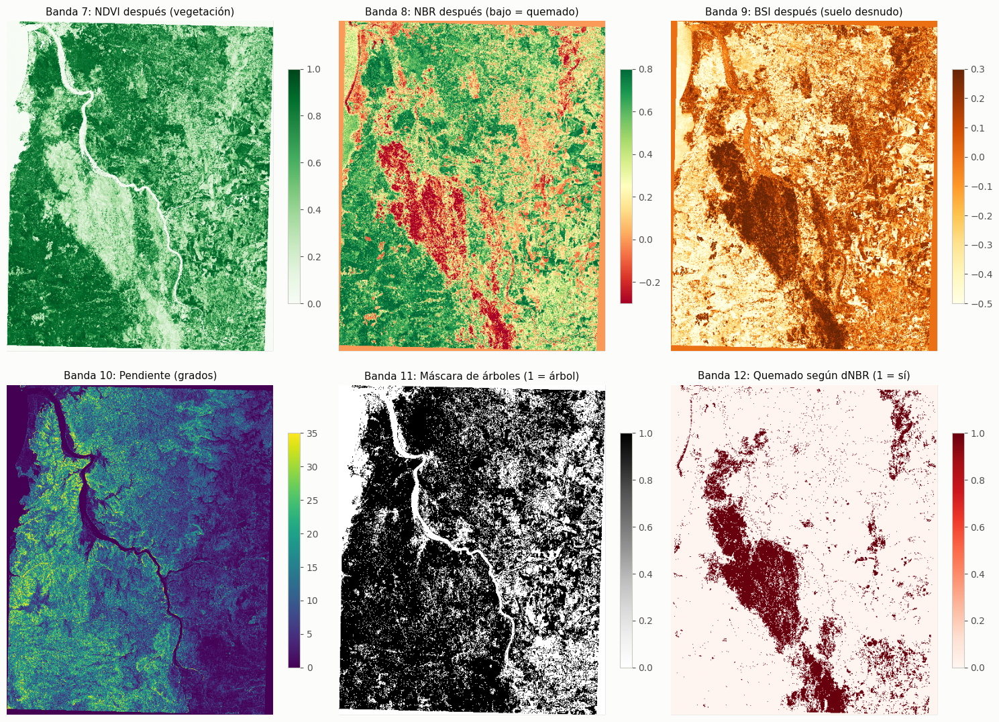

In [25]:
# Mismo mapa, pero con varias de las 13 bandas
def mosaico(banda, escala):
    lienzo = np.full((H // F + 1, W // F + 1), np.nan, np.float32)
    for f, path in zip(filas, tifs):
        with rasterio.open(path) as src:
            h, w = max(src.height // F, 1), max(src.width // F, 1)
            a = src.read(banda, out_shape=(h, w), resampling=Resampling.nearest).astype(np.float32)
        a[a == NODATA] = np.nan
        r, c = f["fila_px"] // F, f["col_px"] // F
        lienzo[r:r + h, c:c + w] = a / escala
    return lienzo

capas = [  # (banda, título, escala, colores, mínimo, máximo)
    (7,  "NDVI después (vegetación)",      1e4, "Greens",  0,    1),
    (8,  "NBR después (bajo = quemado)",   1e4, "RdYlGn", -0.3,  0.8),
    (9,  "BSI después (suelo desnudo)",    1e4, "YlOrBr", -0.5,  0.3),
    (10, "Pendiente (grados)",             100, "viridis", 0,    35),
    (11, "Máscara de árboles (1 = árbol)", 1,   "Greys",   0,    1),
    (12, "Quemado según dNBR (1 = sí)",    1,   "Reds",    0,    1),
]
fig, axs = plt.subplots(2, 3, figsize=(15, 11))
for ax, (b, tit, esc, cmap, vmin, vmax) in zip(axs.flat, capas):
    im = ax.imshow(mosaico(b, esc), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(f"Banda {b}: {tit}")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

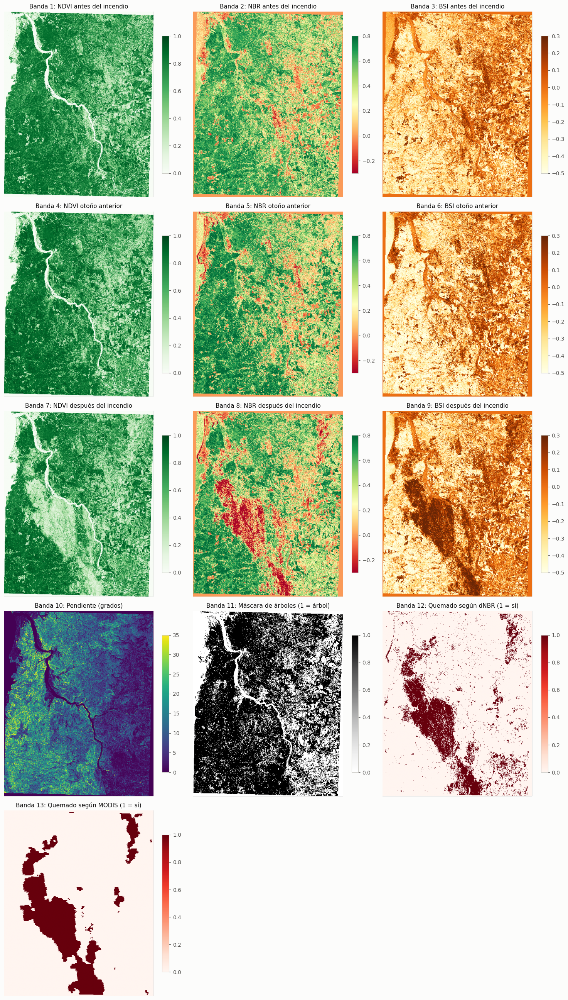

In [26]:
# Las 13 bandas de la zona completa, ordenadas por fecha
def mosaico(banda, escala):
    lienzo = np.full((H // F + 1, W // F + 1), np.nan, np.float32)
    for f, path in zip(filas, tifs):
        with rasterio.open(path) as src:
            h, w = max(src.height // F, 1), max(src.width // F, 1)
            a = src.read(banda, out_shape=(h, w), resampling=Resampling.nearest).astype(np.float32)
        a[a == NODATA] = np.nan
        r, c = f["fila_px"] // F, f["col_px"] // F
        lienzo[r:r + h, c:c + w] = a / escala
    return lienzo

estilo = {  # mismos colores y rango para cada índice, en cualquier fecha
    "NDVI": ("Greens", 0, 1),
    "NBR":  ("RdYlGn", -0.3, 0.8),
    "BSI":  ("YlOrBr", -0.5, 0.3),
}
fechas = [("preV", "antes del incendio"), ("preO", "otoño anterior"), ("post", "después del incendio")]

capas = []
b = 1
for clave, nombre in fechas:
    for ind in ("NDVI", "NBR", "BSI"):
        cmap, vmin, vmax = estilo[ind]
        capas.append((b, f"{ind} {nombre}", 1e4, cmap, vmin, vmax))
        b += 1
capas += [
    (10, "Pendiente (grados)",             100, "viridis", 0, 35),
    (11, "Máscara de árboles (1 = árbol)", 1,   "Greys",   0, 1),
    (12, "Quemado según dNBR (1 = sí)",    1,   "Reds",    0, 1),
    (13, "Quemado según MODIS (1 = sí)",   1,   "Reds",    0, 1),
]

fig, axs = plt.subplots(5, 3, figsize=(15, 26))
for ax in axs.flat:
    ax.axis("off")
for ax, (b, tit, esc, cmap, vmin, vmax) in zip(axs.flat, capas):
    im = ax.imshow(mosaico(b, esc), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(f"Banda {b}: {tit}", fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

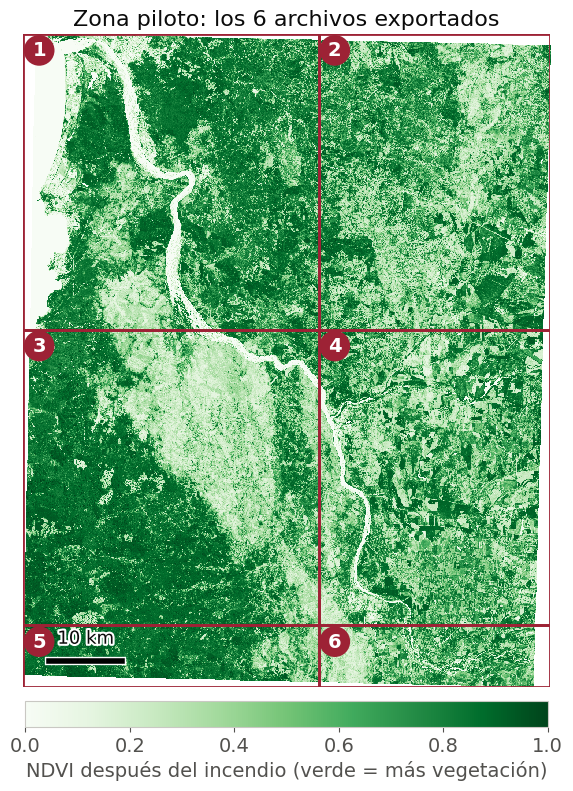

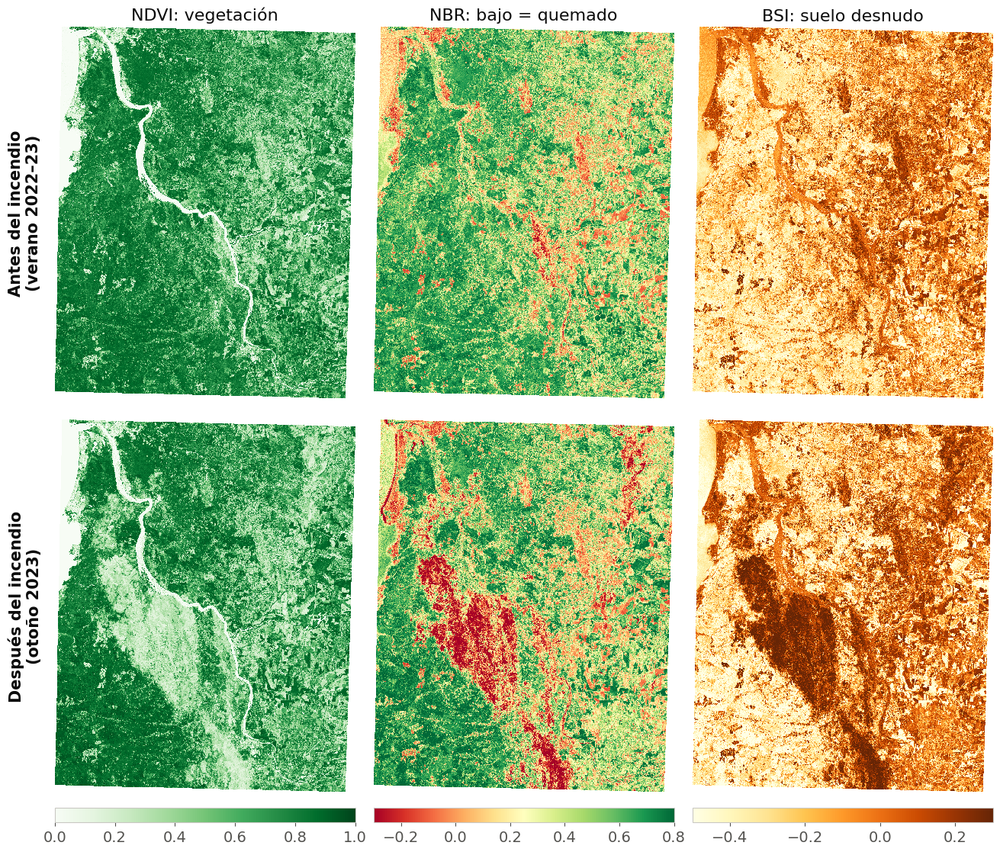

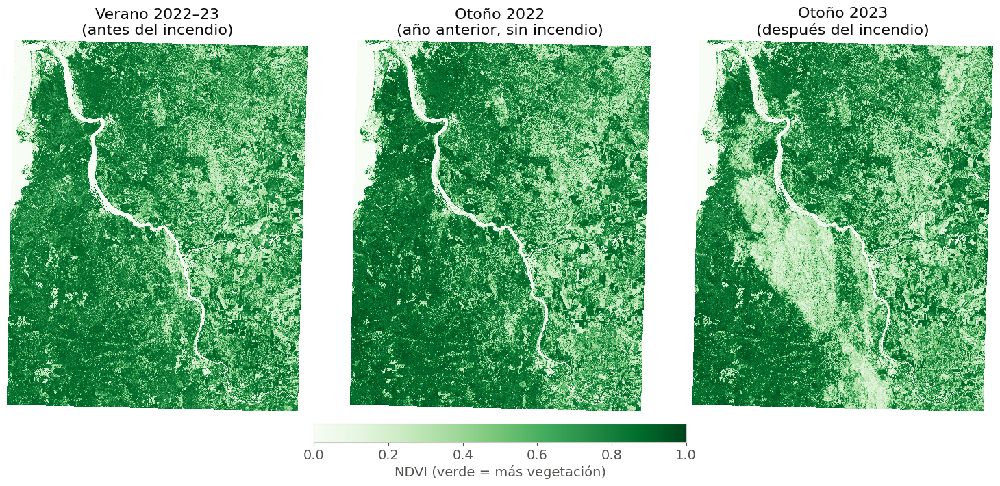

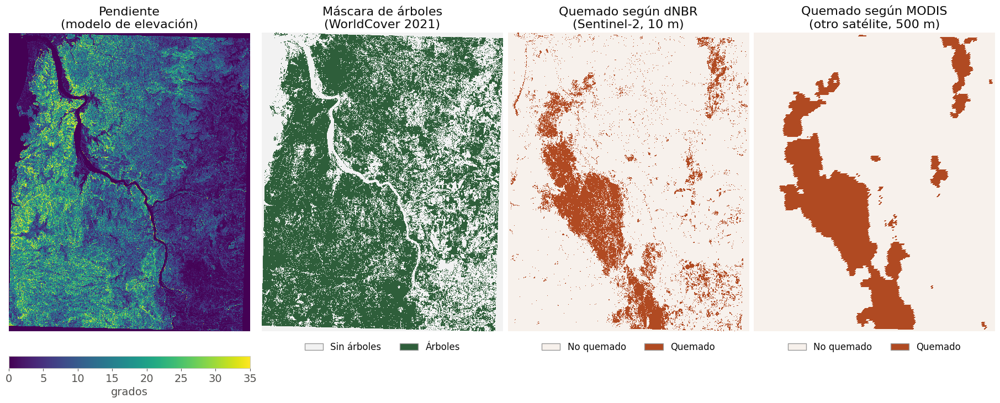

Figuras guardadas en c:\Users\mario\Desktop\Generative Deep Learning Proyecto\runs\figs


In [27]:
# Figuras para la presentación (formato ancho, letra grande, fondo blanco)
import glob, os, re
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import rasterio
from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

RAW_DIR = globals().get("RAW_DIR", "./data/raw")
FIG_DIR = globals().get("FIG_DIR", "./runs/figs")
NODATA = globals().get("NODATA", -32768)
os.makedirs(FIG_DIR, exist_ok=True)
F = 8  # se lee 1 de cada 8 píxeles (80 m): buen detalle para una diapositiva

plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "figure.facecolor": "white",
                     "savefig.facecolor": "white", "savefig.bbox": "tight", "savefig.dpi": 200})

# Ubicar los 6 archivos dentro de la imagen completa
tifs = sorted(glob.glob(os.path.join(RAW_DIR, "*.tif")))
piezas = []
for path in tifs:
    m = re.search(r"-(\d{10})-(\d{10})\.tif$", path)
    r0, c0 = (int(m.group(1)), int(m.group(2))) if m else (0, 0)
    with rasterio.open(path) as src:
        piezas.append((path, r0, c0, src.height, src.width))
H = max(r0 + h for _, r0, _, h, _ in piezas)
W = max(c0 + w for _, _, c0, _, w in piezas)

_cache = {}
def mosaico(banda, escala):
    if banda in _cache:
        return _cache[banda]
    lienzo = np.full((-(-H // F), -(-W // F)), np.nan, np.float32)
    for path, r0, c0, h0, w0 in piezas:
        h, w = -(-h0 // F), -(-w0 // F)
        with rasterio.open(path) as src:
            a = src.read(banda, out_shape=(h, w), resampling=Resampling.nearest).astype(np.float32)
        malo = a == NODATA
        if escala == 1e4:          # en los índices, el borde vacío viene como 0
            malo |= a == 0
        a[malo] = np.nan
        r, c = r0 // F, c0 // F
        hh, ww = min(h, lienzo.shape[0] - r), min(w, lienzo.shape[1] - c)
        lienzo[r:r + hh, c:c + ww] = a[:hh, :ww] / escala
    _cache[banda] = lienzo
    return lienzo

def mapa(ax, datos, cmap, vmin, vmax, titulo):
    im = ax.imshow(datos, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(titulo)
    ax.axis("off")
    return im

def barra_escala(ax, km=10):
    largo = km * 1000 / (10 * F)
    x0, y = (W / F) * 0.05, (H / F) * 0.96
    borde = [pe.withStroke(linewidth=6, foreground="white")]
    ax.plot([x0, x0 + largo], [y, y], color="black", lw=4, path_effects=borde)
    ax.text(x0 + largo / 2, y - (H / F) * 0.02, f"{km} km", ha="center", va="bottom",
            fontsize=13, path_effects=[pe.withStroke(linewidth=3, foreground="white")])

# 1) Zona piloto con los 6 archivos
fig, ax = plt.subplots(figsize=(6.5, 7.8), constrained_layout=True)
im = mapa(ax, mosaico(7, 1e4), "Greens", 0, 1, "Zona piloto: los 6 archivos exportados")
for i, (_, r0, c0, h0, w0) in enumerate(piezas, 1):
    ax.add_patch(plt.Rectangle((c0 / F, r0 / F), w0 / F, h0 / F, fill=False, ec="#9D2235", lw=2))
    ax.text(c0 / F + 28, r0 / F + 28, str(i), color="white", fontsize=14, weight="bold",
            ha="center", va="center", bbox=dict(boxstyle="circle,pad=0.3", fc="#9D2235", ec="none"))
barra_escala(ax)
fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02,
             label="NDVI después del incendio (verde = más vegetación)")
fig.savefig(os.path.join(FIG_DIR, "ppt_zona_archivos.png")); plt.show()

# 2) Antes vs después del incendio
columnas = [("NDVI: vegetación", 1, 7, "Greens", 0, 1),
            ("NBR: bajo = quemado", 2, 8, "RdYlGn", -0.3, 0.8),
            ("BSI: suelo desnudo", 3, 9, "YlOrBr", -0.5, 0.3)]
fig, axs = plt.subplots(2, 3, figsize=(13, 11), constrained_layout=True)
for j, (tit, b_antes, b_desp, cmap, vmin, vmax) in enumerate(columnas):
    mapa(axs[0, j], mosaico(b_antes, 1e4), cmap, vmin, vmax, tit)
    im = mapa(axs[1, j], mosaico(b_desp, 1e4), cmap, vmin, vmax, "")
    fig.colorbar(im, ax=axs[:, j], orientation="horizontal", fraction=0.035, pad=0.02)
for i, txt in enumerate(["Antes del incendio\n(verano 2022–23)", "Después del incendio\n(otoño 2023)"]):
    axs[i, 0].text(-0.1, 0.5, txt, transform=axs[i, 0].transAxes, rotation=90,
                   ha="center", va="center", fontsize=15, weight="bold")
fig.savefig(os.path.join(FIG_DIR, "ppt_antes_despues.png")); plt.show()

# 3) Efecto de la estación vs efecto del incendio (NDVI)
fig, axs = plt.subplots(1, 3, figsize=(15, 7), constrained_layout=True)
for ax, (b, tit) in zip(axs, [(1, "Verano 2022–23\n(antes del incendio)"),
                              (4, "Otoño 2022\n(año anterior, sin incendio)"),
                              (7, "Otoño 2023\n(después del incendio)")]):
    im = mapa(ax, mosaico(b, 1e4), "Greens", 0, 1, tit)
fig.colorbar(im, ax=axs, orientation="horizontal", fraction=0.05, pad=0.03,
             label="NDVI (verde = más vegetación)")
fig.savefig(os.path.join(FIG_DIR, "ppt_estacion.png")); plt.show()

# 4) Pendiente, máscara y etiquetas de quemado
fig, axs = plt.subplots(1, 4, figsize=(18, 7), constrained_layout=True)
im = mapa(axs[0], mosaico(10, 100), "viridis", 0, 35, "Pendiente\n(modelo de elevación)")
fig.colorbar(im, ax=axs[0], orientation="horizontal", fraction=0.05, pad=0.03, label="grados")
binarias = [(11, "Máscara de árboles\n(WorldCover 2021)", ["#F2F2F2", "#2E5E3A"], ["Sin árboles", "Árboles"]),
            (12, "Quemado según dNBR\n(Sentinel-2, 10 m)", ["#F7F1EC", "#B04A22"], ["No quemado", "Quemado"]),
            (13, "Quemado según MODIS\n(otro satélite, 500 m)", ["#F7F1EC", "#B04A22"], ["No quemado", "Quemado"])]
for ax, (b, tit, colores, etiquetas) in zip(axs[1:], binarias):
    mapa(ax, mosaico(b, 1), ListedColormap(colores), 0, 1, tit)
    ax.legend(handles=[Patch(fc=c, ec="#999999", label=e) for c, e in zip(colores, etiquetas)],
              loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=False, fontsize=12)
fig.savefig(os.path.join(FIG_DIR, "ppt_pendiente_mascara_etiquetas.png")); plt.show()

print("Figuras guardadas en", os.path.abspath(FIG_DIR))

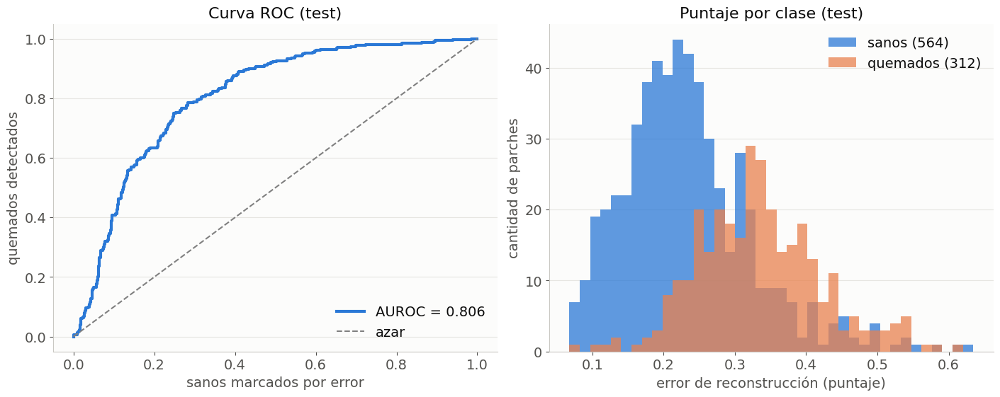

In [28]:
# (Opcional) Curva ROC e histograma del baseline, con letra grande
from sklearn.metrics import roc_curve, roc_auc_score
if "y_t" in globals():
    y, e = np.asarray(y_t), np.asarray(e_t)
    fpr, tpr, _ = roc_curve(y, e)
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    axs[0].plot(fpr, tpr, color="#2A78D6", lw=3, label=f"AUROC = {roc_auc_score(y, e):.3f}")
    axs[0].plot([0, 1], [0, 1], "--", color="gray", lw=1.5, label="azar")
    axs[0].set(xlabel="sanos marcados por error", ylabel="quemados detectados", title="Curva ROC (test)")
    axs[0].legend(loc="lower right", frameon=False)
    bins = np.linspace(np.percentile(e, 0.5), np.percentile(e, 99.5), 40)
    axs[1].hist(e[y == 0], bins=bins, alpha=0.75, color="#2A78D6", label=f"sanos ({(y == 0).sum()})")
    axs[1].hist(e[y == 1], bins=bins, alpha=0.75, color="#E9824F", label=f"quemados ({(y == 1).sum()})")
    axs[1].set(xlabel="error de reconstrucción (puntaje)", ylabel="cantidad de parches",
               title="Puntaje por clase (test)")
    axs[1].legend(frameon=False)
    for a in axs:
        a.spines[["top", "right"]].set_visible(False)
    fig.savefig(os.path.join(FIG_DIR, "ppt_roc_histograma.png")); plt.show()
else:
    print("Primero corre la celda del AUROC de test (sección del baseline E1).")